In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
def load_power_spectrum(file):

    path = '/home/biel/Hi-COLA/Hi-COLA_Output/'
    
    table = pd.read_csv(path+file,
    sep=r"\s+",
    comment="#",
    names=["k (h/Mpc)", "P_k (Mpc/h)^3", "P_linear_k (Mpc/h)^3"])

    k = table["k (h/Mpc)"]
    Pk = table["P_k (Mpc/h)^3"]
    
    return k, Pk

In [4]:
def plot_power_spectrum(k, Pk):

    fig, ax = plt.subplots(figsize=(6.5, 5.5), dpi=300)

    ax.loglog(k, Pk, lw=2)

    ax.set_xlabel(r"$k \; [h/\mathrm{Mpc}]$", fontsize=14)
    ax.set_ylabel(r"$P(k)[(\mathrm{Mpc}/h)^3]$", fontsize=14)

    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.tick_params(axis='both', which='minor', labelsize=10)

    plt.tight_layout()
    plt.savefig("fig/power_spectrum.png")
    plt.show()

In [5]:
def compare_power_spectrum(ks, Pks, labels):

    fig, ax = plt.subplots(figsize=(6.5, 5.5), dpi=300)

    for i in range(len(ks)):
        ax.loglog(ks[i], Pks[i], lw=2, label=labels[i])

    ax.set_xlabel(r"$k \; [h/\mathrm{Mpc}]$", fontsize=14)
    ax.set_ylabel(r"$P(k)[(\mathrm{Mpc}/h)^3]$", fontsize=14)

    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.tick_params(axis='both', which='minor', labelsize=10)

    plt.tight_layout()
    plt.legend()
    plt.savefig("fig/power_spectrum.png")
    plt.show()

In [10]:
k_LCDM, Pk_LCDM = load_power_spectrum('LCDM_test/snapshot_LCDM_test_z0.000/pofk_z0.000.txt')
k_cuGal, Pk_cuGal = load_power_spectrum('cuGal_test/snapshot_cuGal_test_z0.000/pofk_z0.000.txt')
k_nDGP, Pk_nDGP = load_power_spectrum('nDGP_model/snapshot_nDGP_model_z0.000/pofk_z0.000.txt')

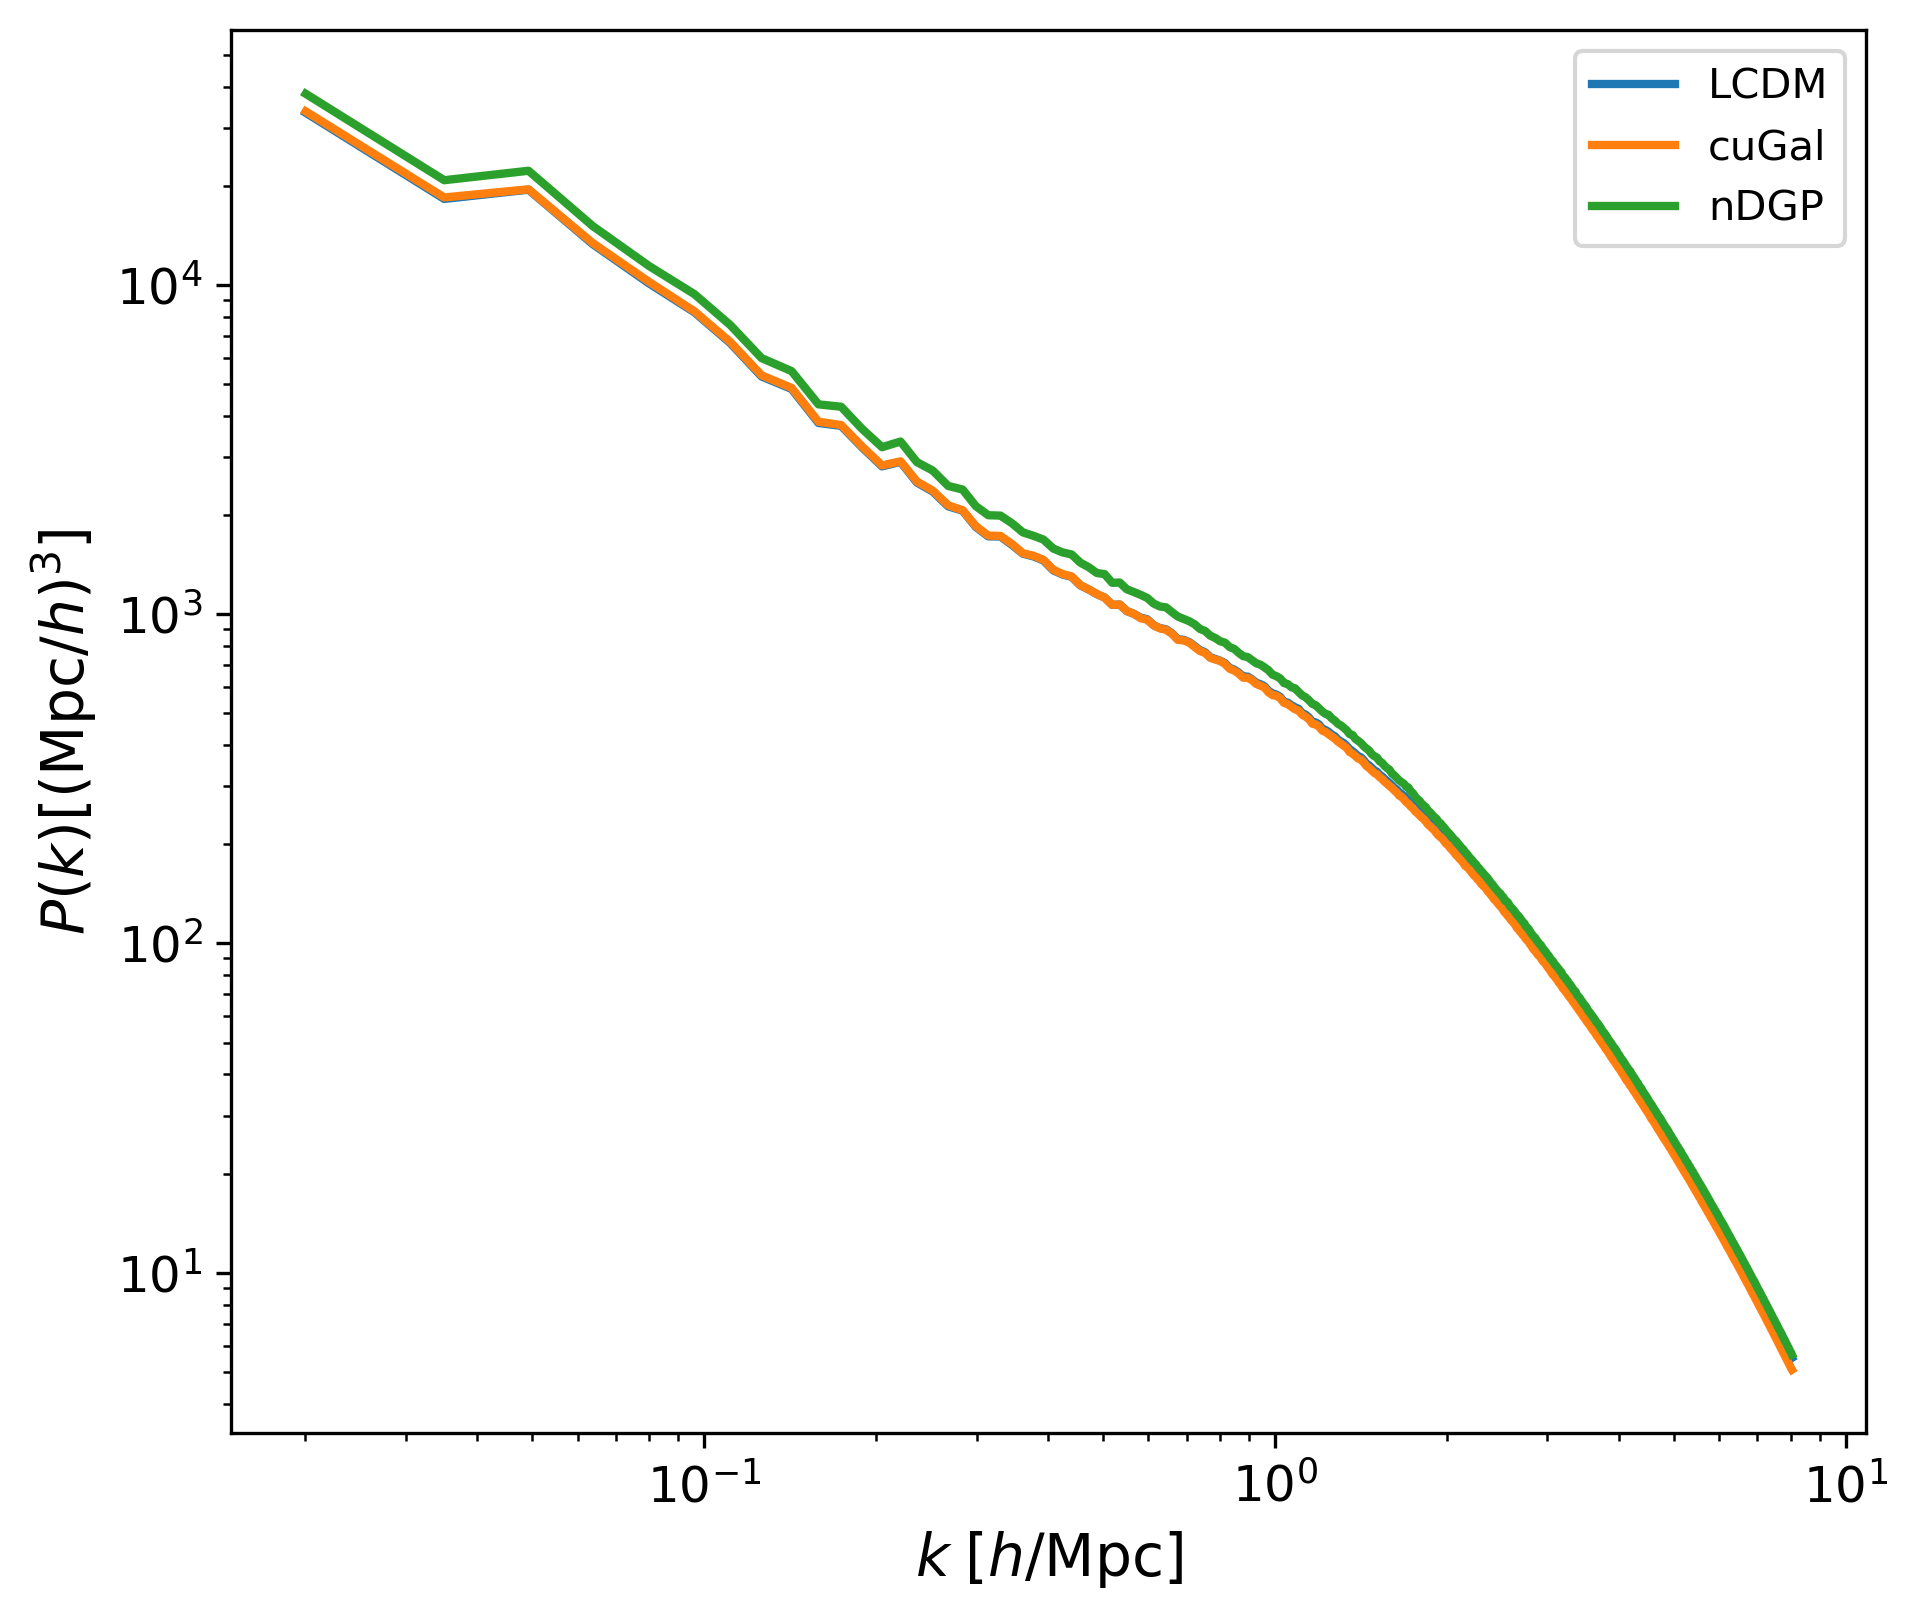

In [12]:
labels = ['LCDM', 'cuGal','nDGP']
compare_power_spectrum([k_LCDM,k_cuGal,k_nDGP], [Pk_LCDM,Pk_cuGal,Pk_nDGP], labels)

In [19]:
def ratio_power_spectrum(k1, Pk1, k2, Pk2, labels):

    fig, ax = plt.subplots(figsize=(8.5, 5.5), dpi=300)

    ax.plot(k1, Pk2/Pk1, lw=2)

    ax.set_xlabel(r"$k \; [h/\mathrm{Mpc}]$", fontsize=14)
    ax.set_ylabel(r"$p^{\mathrm{" + labels[1] + r"}}(k,z=0)/p^{\mathrm{" + labels[0] + r"}}(k,z=0)$", fontsize=14)
    ax.set_xscale('log')
    ax.set_xlim(2e-1,2)

    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.tick_params(axis='both', which='minor', labelsize=10)

    plt.tight_layout()
    plt.savefig("fig/ratio_power_spectrum.png")
    plt.show()

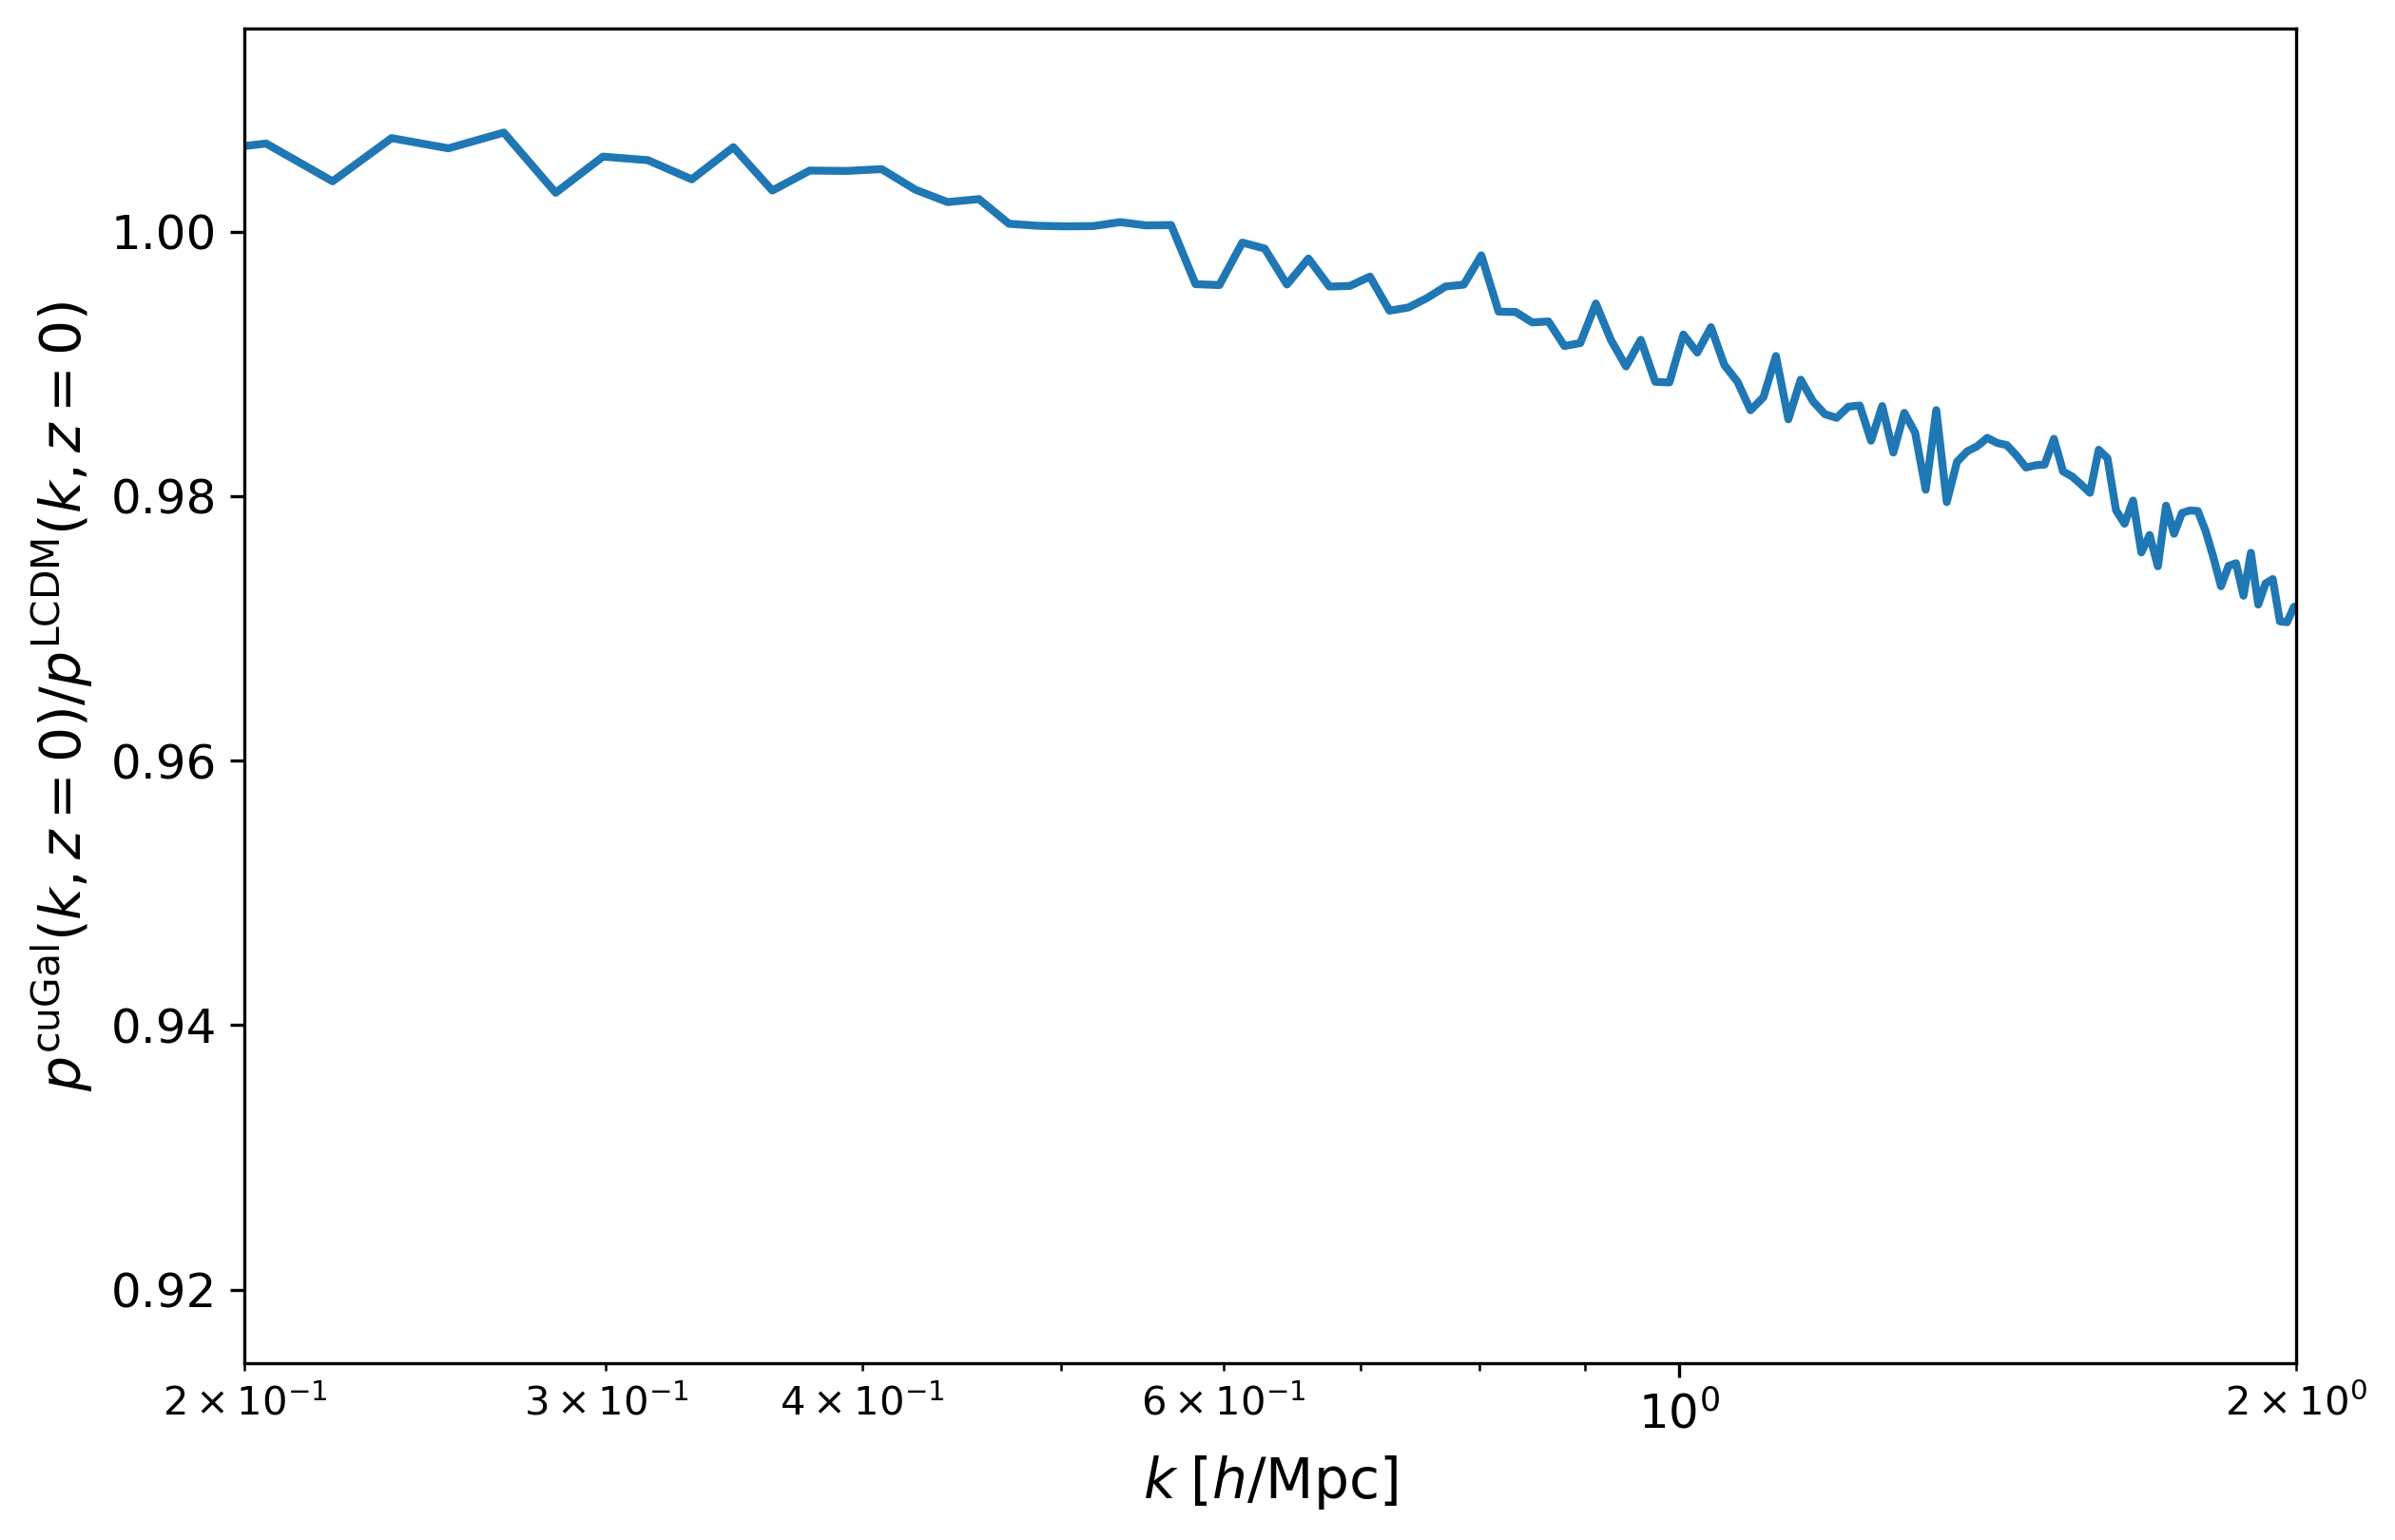

In [20]:
labels = ['LCDM', 'cuGal']
ratio_power_spectrum(k_LCDM,Pk_LCDM,k_cuGal,Pk_cuGal,labels)

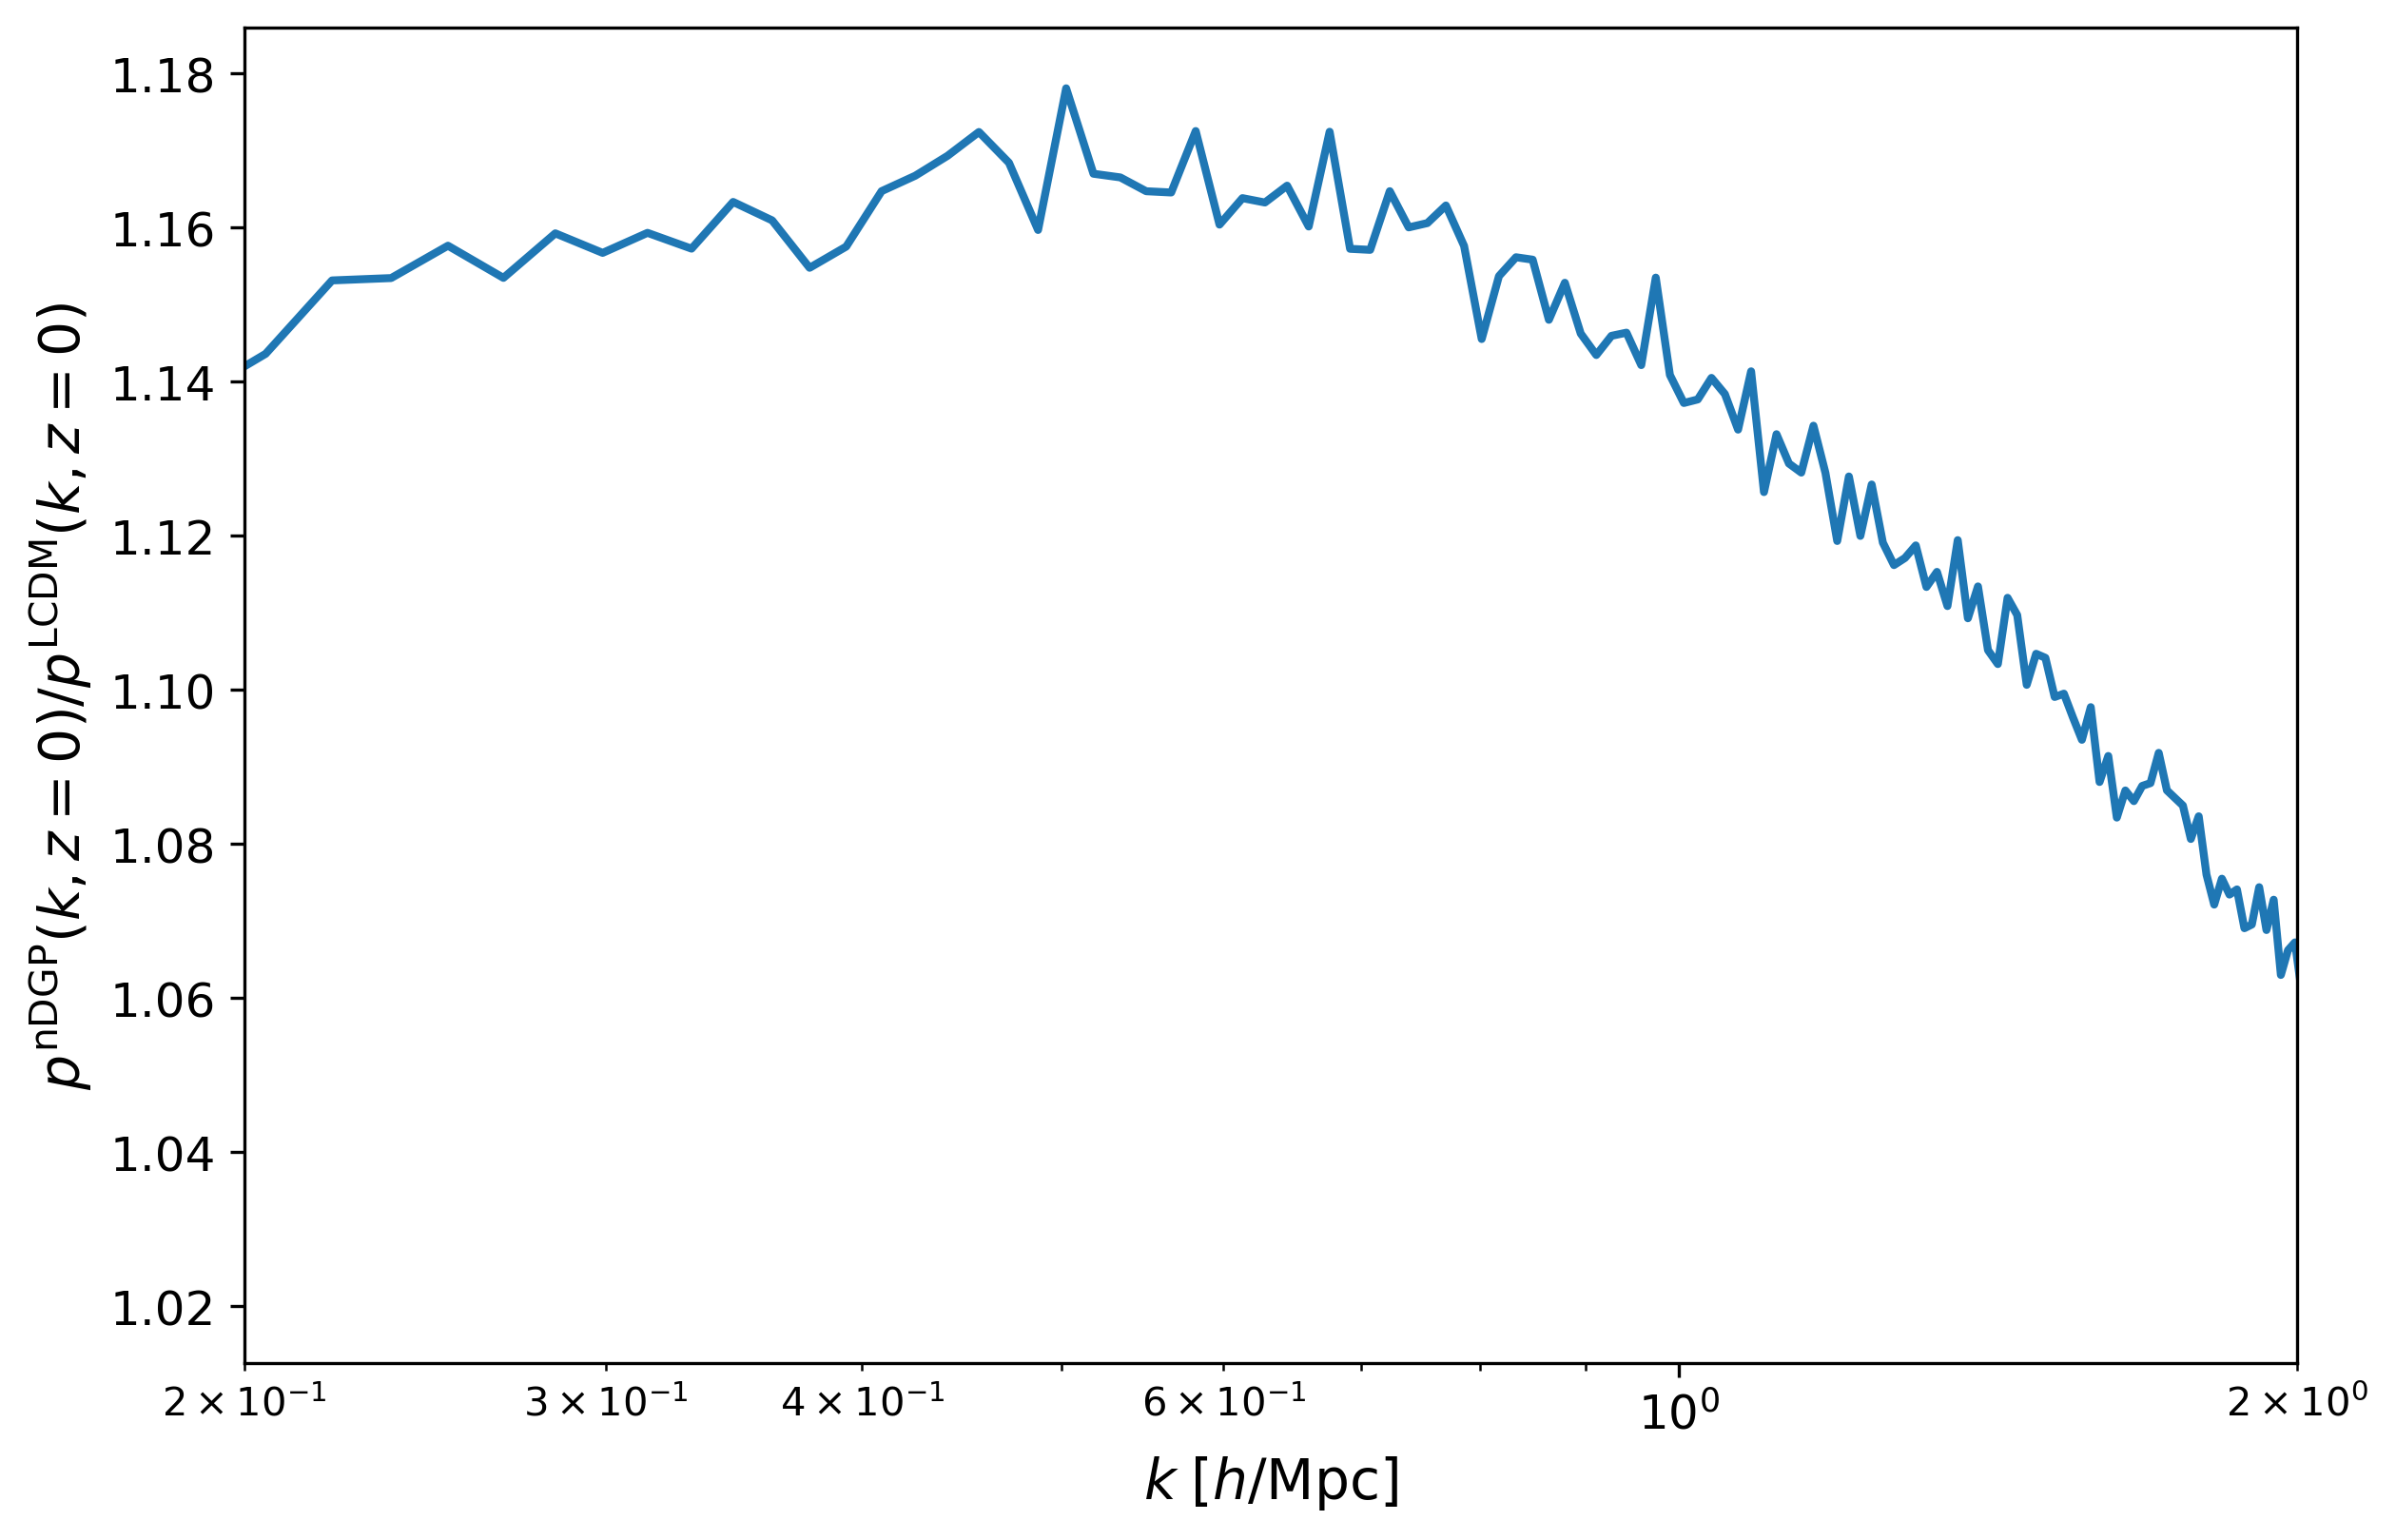

In [21]:
labels = ['LCDM', 'nDGP']
ratio_power_spectrum(k_LCDM,Pk_LCDM,k_nDGP,Pk_nDGP,labels)

In [9]:
path_cuGal = '/home/bielthi/Hi-COLA/Hi-COLA_Output/simulations/'
redshifts = ['0.000', '0.244','0.645', '1.427', '3.630', '49.000']
names_cuGal = ['pofk_cuGal_cb_z{}.txt'.format(redshift) for redshift in redshifts]
files_cuGal = [path_cuGal + name_cuGal for name_cuGal in names_cuGal]

In [10]:
ks_cuGal, Pks_cuGal = [], []
for i in range(len(redshifts)):
    k_cuGal, Pk_cuGal = load_power_spectrum(files_cuGal[i])
    ks_cuGal.append(k_cuGal)
    Pks_cuGal.append(Pk_cuGal)

FileNotFoundError: [Errno 2] No such file or directory: '/home/biel/Hi-COLA/Hi-COLA_Output//home/bielthi/Hi-COLA/Hi-COLA_Output/simulations/pofk_cuGal_cb_z0.000.txt'

In [ ]:
labels = ['z={}'.format(redshift) for redshift in redshifts]
compare_power_spectrum(ks_cuGal, Pks_cuGal, labels)

In [ ]:
path_LCDM = '/home/bielthi/Hi-COLA/Hi-COLA_Output/simulations/'
redshifts = ['0.000', '0.244','0.645', '1.427', '3.630', '49.000']
names_LCDM = ['pofk_LCDM_cb_z{}.txt'.format(redshift) for redshift in redshifts]
files_LCDM = [path_LCDM + name_LCDM for name_LCDM in names_LCDM]

In [ ]:
ks_LCDM, Pks_LCDM = [], []
for i in range(len(redshifts)):
    k_LCDM, Pk_LCDM = load_power_spectrum(files_LCDM[i])
    ks_LCDM.append(k_LCDM)
    Pks_LCDM.append(Pk_LCDM)

In [ ]:
labels = ['z={}'.format(redshift) for redshift in redshifts]
compare_power_spectrum(ks_LCDM, Pks_LCDM, labels)

In [ ]:
(Pks_cuGal[0] - Pks_LCDM[0]) / Pks_LCDM[0]